# Introduction to Generative Adversarial Networks (GANs)

In this notebook, we will introduce Generative Adversarial Networks (GANs) and implement a simple GAN using PyTorch. We will first discuss the basic concepts of GANs and training models on 2D data. Then, we will implement a GAN to generate handwritten digits from the MNIST dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import DataLoader

import torchvision.transforms as transforms
import torchvision.datasets as datasets

First let us define the device to work on:

In [2]:
print(f"GPU available using Cuda: {torch.cuda.is_available()}")
print(
    f"GPU available using MPS: {torch.backends.mps.is_available() and torch.backends.mps.is_built()}"
)
if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_available = True
elif torch.backends.mps.is_available() and torch.backends.mps.is_built():
    device = torch.device("mps")
    gpu_available = True
else:
    device = torch.device("cpu")
    gpu_available = False


print(f"Device: {device}")
print(f"Number of GPUs: {torch.cuda.device_count()}")

GPU available using Cuda: True
GPU available using MPS: False
Device: cuda
Number of GPUs: 2


# 1 The GAN Model

Generative Adversarials Networks (GANs) are a class of generative models that are used to generate new data samples. GANs consist of two neural networks, a generator and a discriminator, that are trained simultaneously. The generator generates new data samples, while the discriminator tries to distinguish between real and generated samples. The generator and discriminator are trained in an adversarial manner, where the generator tries to generate samples that are indistinguishable from real samples, and the discriminator tries to distinguish between real and generated samples.

## 1.1 The Generator

One easy way to thing about the generator is as a function that takes random noise as input and generates new data samples. The generator is a neural network that takes random noise as input and generates new data samples. The generator is trained to generate samples that are indistinguishable from real samples. 

Typically the generator is a feedforward neural network that takes random noise as input in $R^d$ and generates samples in $R^D$. The distribution of the output is the generated distribution. Typically, the input noise is sampled from a normal distribution and for instance, if the generator function is linear:


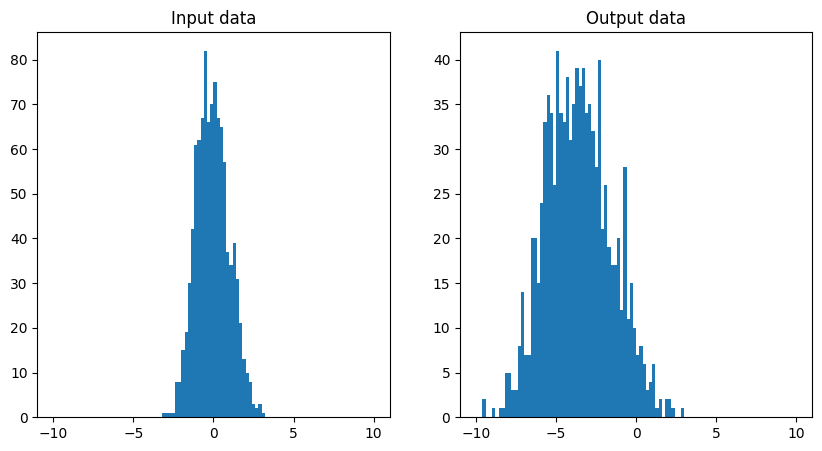

In [3]:
def input_noise(n=1000, noise_dim=1):
    return torch.randn(n, noise_dim)


def generator_function(x):
    return 2 * x - 3.5


input_data = input_noise()
output_data = generator_function(input_data)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(input_data.numpy(), bins=100, range=(-10, 10))
plt.title("Input data")
plt.subplot(1, 2, 2)
plt.hist(output_data.numpy(), bins=100, range=(-10, 10))
plt.title("Output data")
plt.show()

The generator can be implemented with a neural network to represent more complex functions.

## 1.2 The Discriminator

Let us assume that we have a target distribution $p_{\text{data}}(x)$ and a generator distribution $p_{\text{model}}(x)$. The discriminator is trained to distinguish between samples from the target distribution and the generator distribution. The discriminator is trained to differentiate between samples from the target distribution and the generator distribution. In other words, the discriminator outputs the probability that a sample is from the target distribution:

In [4]:
def target_density(x):
    return 0.5 * torch.exp(
        torch.distributions.Normal(-4, 1).log_prob(x)
    ) + 0.5 * torch.exp(torch.distributions.Normal(4, 1).log_prob(x))


def model_density(x):
    return torch.exp(torch.distributions.Normal(-3.5, 2).log_prob(x))

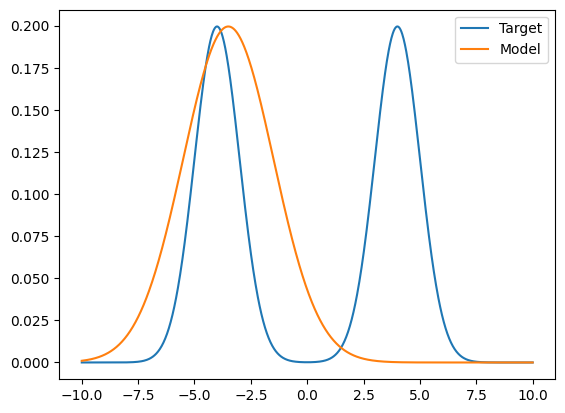

In [5]:
x = torch.linspace(-10, 10, 1000)
plt.plot(x, target_density(x), label="Target")
plt.plot(x, model_density(x), label="Model")
plt.legend()

The optimal discriminator is given by:
$$D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_{\text{model}}(x)}$$

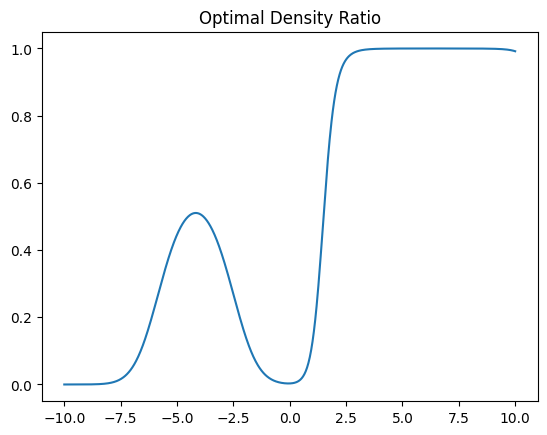

In [6]:
Dopt = target_density(x) / (target_density(x) + model_density(x))
plt.figure()
plt.plot(x, Dopt)
plt.title("Optimal Density Ratio")
plt.show()

The Generator is trained to generate samples that are indistinguishable from samples from the target distribution. In other words, the generator tries to generate samples with the highest probability of being from the target distribution.
We will now implement a simple GAN on 2D data.

# 2. GAN on two dimensional data Gaussian Mixture

In this section, we will implement a simple GAN on 2D data. We will generate samples from a Gaussian Mixture distribution and train a GAN to generate samples from the same distribution using PyTorch.
We will implement a linear generator and discriminator for this task, then move on to more complex models. 


## 1.1 Training loop on simple data with linear models

First let us visualize the data:

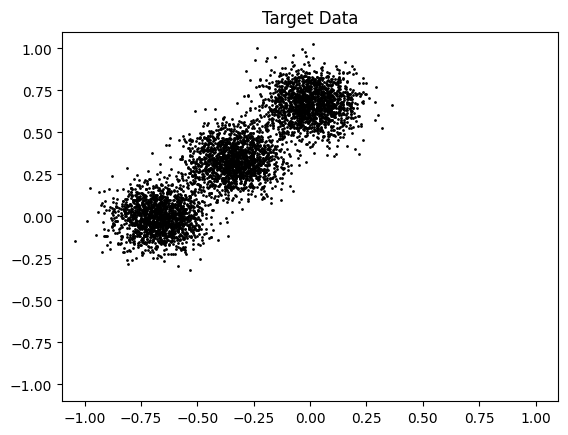

In [7]:
def simple_2D_data(n=1000):
    means = torch.Tensor([[-4, 0], [0, 4], [-2, 2]])
    sigmas = torch.Tensor([0.6] * 3)
    n_per_cluster = n // 3
    data = []
    for i in range(3):
        data.append(
            torch.distributions.Normal(means[i], sigmas[i]).sample((n_per_cluster,))
        )
    data = torch.cat(data) / 6
    return data


dataset = simple_2D_data(n=5000)
plt.scatter(dataset[:, 0], dataset[:, 1], c="black", s=1)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.title("Target Data")
plt.show()

<font color='blue'>**TODO:**</font> Complete the code below to implement a linear generator and discriminator:
- The generator should be a linear layer that takes an input noise in dimension `noise_dim` and outputs a sample in dimension 2. You can add output activation if needed.
- The discriminator should be a linear layer that takes an input sample in dimension 2 and outputs a probability that the sample is from the target distribution. The output should be a scalar between 0 and 1. You can add output activation if needed.

```python

In [8]:
class LinearGenerator(nn.Module):
    def __init__(self, noise_dim=1):
        super(LinearGenerator, self).__init__()
        self.fc1 = nn.Linear(noise_dim, 2)
        self.out_activation = nn.Tanh()

    def forward(self, x):
        x = self.fc1(x)
        return self.out_activation(x)


class LinearDiscriminator(nn.Module):
    def __init__(self):
        super(LinearDiscriminator, self).__init__()
        self.fc1 = nn.Linear(2, 1)
        self.out_activation = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        return self.out_activation(x)

Let us the both models:

In [9]:
def visualize_generator(generator, noise_dim, n=1000):
    noise = input_noise(n, noise_dim=noise_dim).to(device)
    generated_data = generator(noise).detach().cpu()
    plt.figure()
    plt.scatter(generated_data[:, 0], generated_data[:, 1], c="blue", s=1)
    plt.xlim(-1.1, 1.1)
    plt.ylim(-1.1, 1.1)
    plt.title("Generated Data")
    plt.show()


def visualize_discriminator(discriminator, n=1000):
    x = torch.linspace(-1, 1, n)
    y = torch.linspace(-1, 1, n)
    xx, yy = torch.meshgrid(x, y)
    grid = (
        torch.from_numpy(np.stack([xx, yy], axis=-1).reshape(-1, 2)).float().to(device)
    )
    with torch.no_grad():
        predictions = discriminator(grid).cpu().view(n, n)
    plt.imshow(predictions.T, extent=(-1, 1, -1, 1), origin="lower")
    plt.colorbar()
    plt.title("Discriminator Output")
    plt.show()


def visualize_loss(loss_D, loss_G):
    plt.figure()
    plt.plot(loss_D, label="Discriminator Loss")
    plt.plot(loss_G, label="Generator Loss")
    plt.legend()
    plt.title("Losses")
    plt.show()

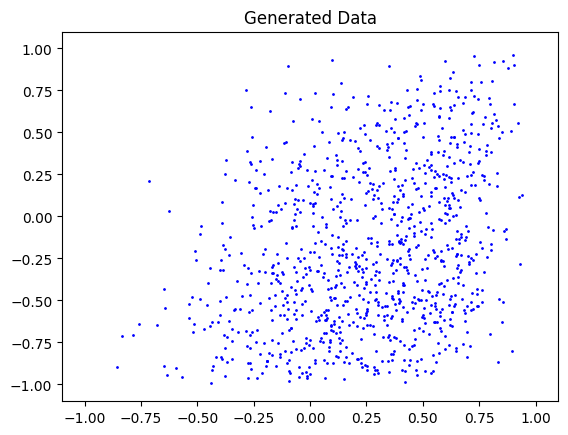

/home/lamsade/averine/venv/lib/python3.13/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4317.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


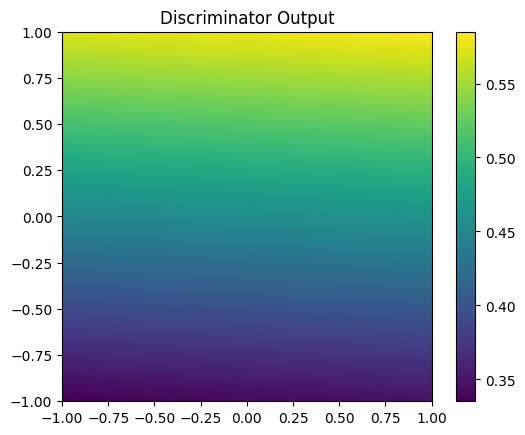

In [10]:
noise_dim = 10
generator = LinearGenerator(noise_dim).to(device)
discriminator = LinearDiscriminator().to(device)

visualize_generator(generator, noise_dim)
visualize_discriminator(discriminator)

Since the discriminator is trained to differentiate between samples from the target distribution and the generator distribution, we can train it as a binary classifier. Let us say that the point from the target distribution is labeled as 1 and the point from the generator distribution is labeled as 0.

<font color='blue'>**TODO:**</font> Complete the code below to implement the training loss for the discriminator using the binary cross entropy loss ```torch.nn.BCELoss``` [(Doc)](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html). The discriminator should output the probability that the sample is from the target distribution. The target should be 1 for samples from the target distribution and 0 for samples from the generator distribution.


In [11]:
criterion = nn.BCELoss()


def discriminator_loss(output_real, output_fake):
    real_labels = torch.ones_like(output_real)
    fake_labels = torch.zeros_like(output_fake)

    real_loss = criterion(output_real, real_labels)
    fake_loss = criterion(output_fake, fake_labels)

    return real_loss + fake_loss


def discriminator_loss(output_real, output_fake):
    real_labels = torch.ones_like(output_real)
    fake_labels = torch.zeros_like(output_fake)

    outputs = torch.cat([output_real, output_fake], dim=0)
    labels = torch.cat([real_labels, fake_labels], dim=0)

    return criterion(outputs, labels)

The generator loss is the opposite of the discriminator loss. We can write it as the Binary Cross Entropy loss with the labels flipped.

<font color='blue'>**TODO:**</font> Complete the code below to implement the training loss for the generator. 



In [12]:
def generator_loss(output_fake):
    fake_labels = torch.ones_like(output_fake)
    return criterion(output_fake, fake_labels)

<font color='blue'>**TODO:**</font>  Run the code below to make sure that the training losses are implemented correctly.


In [13]:
noise_dim = 10
noise = input_noise(1000, noise_dim=noise_dim).to(device)
data = simple_2D_data(n=5000).to(device)

generator = LinearGenerator(noise_dim).to(device)
discriminator = LinearDiscriminator().to(device)

print(
    "The discriminator loss is: ",
    discriminator_loss(discriminator(data), discriminator(generator(noise))),
)
print("The generator loss is: ", generator_loss(discriminator(generator(noise))))

The discriminator loss is:  tensor(0.6509, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward0>)
The generator loss is:  tensor(0.4984, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward0>)


The training loop for the GAN consists in alternating a gradient step on the discriminator and the generator:
1. Sample a batch a data from the target distribution.
2. Sample a batch of noise from a normal distribution with the same batch size.
3. Generate samples from the generator.
4. Compute the discriminator loss based on real and generated samples.
5. Apply a gradient step on the discriminator.
6. Compute the generator loss based on generated samples.
7. Apply a gradient step on the generator.

<font color='blue'>**TODO:**</font> Complete the code below to implement the training step for the GAN. The training step should apply a gradient step on the discriminator and the generator. The training step should return the discriminator and generator losses. 


In [14]:
def training_step(
    generator, discriminator, optimizer_D, optimizer_G, noise, data, num_steps=1
):
    for _ in range(num_steps):
        discriminator.train()
        generator.eval()
        optimizer_D.zero_grad()

        generated_data = generator(noise)
        output_real = discriminator(data)
        output_fake = discriminator(generated_data)

        loss_D = discriminator_loss(output_real, output_fake)
        loss_D.backward()
        optimizer_D.step()

    discriminator.eval()
    generator.train()
    optimizer_G.zero_grad()

    generated_data = generator(noise)
    output_fake = discriminator(generated_data)
    loss_G = generator_loss(output_fake)
    loss_G.backward()
    optimizer_G.step()

    return loss_D.item(), loss_G.item()

<font color='blue'>**TODO:**</font> Run the code below to make sure that the training step is implemented correctly.

In [15]:
noise_dim = 10
batch_size = 100

generator = LinearGenerator(noise_dim).to(device)
discriminator = LinearDiscriminator().to(device)

optimizer_D = optim.Adam(discriminator.parameters(), lr=0.002)
optimizer_G = optim.Adam(generator.parameters(), lr=0.002)

noise = input_noise(n=batch_size, noise_dim=noise_dim).to(device)
data = simple_2D_data(n=batch_size).to(device)

print("Before training")
print(
    "The discriminator loss is: ",
    discriminator_loss(discriminator(data), discriminator(generator(noise))),
)
print("The generator loss is: ", generator_loss(discriminator(generator(noise))))

for _ in range(100):
    loss_D, loss_G = training_step(
        generator, discriminator, optimizer_D, optimizer_G, noise, data
    )

print("\nAfter a few training steps")
print(
    "The discriminator loss is: ",
    discriminator_loss(discriminator(data), discriminator(generator(noise))),
)
print("The generator loss is: ", generator_loss(discriminator(generator(noise))))

Before training
The discriminator loss is:  tensor(0.6847, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward0>)
The generator loss is:  tensor(1.0275, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward0>)

After a few training steps
The discriminator loss is:  tensor(0.6610, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward0>)
The generator loss is:  tensor(0.8517, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward0>)


<font color='blue'>**TODO:**</font>  Complete the code below to implement the training loop for the GAN. At each epoch, we should sample 5000 data points from the target distribution and split them into batches of size `batch_size`. 

In [16]:
def train_GAN(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    sample_function,
    n_epochs=20,
    batch_size=100,
    num_steps=1,
):
    loss_D_values = []
    loss_G_values = []
    noise = input_noise(n=5000, noise_dim=noise_dim).to(device)
    data = sample_function(n=5000).to(device)
    n_batches = len(data) // batch_size
    for epoch in range(n_epochs):
        data = data[torch.randperm(len(data))]
        noise = noise[torch.randperm(len(noise))]
        avg_loss_D = 0
        avg_loss_G = 0

        for i in range(n_batches):
            noise_i = noise[i * batch_size : (i + 1) * batch_size]
            data_i = data[i * batch_size : (i + 1) * batch_size]
            loss_D, loss_G = training_step(
                generator,
                discriminator,
                optimizer_D,
                optimizer_G,
                noise_i,
                data_i,
                num_steps=num_steps,
            )
            loss_D_values.append(loss_D)
            loss_G_values.append(loss_G)
            avg_loss_D += loss_D
            avg_loss_G += loss_G

        print(
            f"Epoch {epoch+1}/{n_epochs} Loss D: {avg_loss_D/n_batches:.4f} Loss G: {avg_loss_G/n_batches:.4f}"
        )

    return loss_D_values, loss_G_values

<font color='blue'>**TODO:**</font> Run the code below to train the GAN on 2D data.

In [17]:
generator = LinearGenerator(noise_dim).to(device)
discriminator = LinearDiscriminator().to(device)

optimizer_D = optim.Adam(discriminator.parameters(), betas=(0.5, 0.9), lr=5e-4)
optimizer_G = optim.Adam(generator.parameters(), betas=(0.5, 0.9), lr=5e-4)

loss_D_values, loss_G_values = train_GAN(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    simple_2D_data,
    n_epochs=20,
    batch_size=100,
    num_steps=5,
)

Epoch 1/20 Loss D: 0.6977 Loss G: 0.8949
Epoch 2/20 Loss D: 0.6651 Loss G: 0.8350
Epoch 3/20 Loss D: 0.6412 Loss G: 0.7837
Epoch 4/20 Loss D: 0.6252 Loss G: 0.7845
Epoch 5/20 Loss D: 0.6127 Loss G: 0.8130
Epoch 6/20 Loss D: 0.6033 Loss G: 0.8372
Epoch 7/20 Loss D: 0.5956 Loss G: 0.8569
Epoch 8/20 Loss D: 0.5909 Loss G: 0.8756
Epoch 9/20 Loss D: 0.5864 Loss G: 0.8877
Epoch 10/20 Loss D: 0.5840 Loss G: 0.8911
Epoch 11/20 Loss D: 0.5828 Loss G: 0.8891
Epoch 12/20 Loss D: 0.5827 Loss G: 0.8823
Epoch 13/20 Loss D: 0.5844 Loss G: 0.8700
Epoch 14/20 Loss D: 0.5879 Loss G: 0.8488
Epoch 15/20 Loss D: 0.5949 Loss G: 0.8265
Epoch 16/20 Loss D: 0.6038 Loss G: 0.8053
Epoch 17/20 Loss D: 0.6163 Loss G: 0.7853
Epoch 18/20 Loss D: 0.6318 Loss G: 0.7660
Epoch 19/20 Loss D: 0.6501 Loss G: 0.7462
Epoch 20/20 Loss D: 0.6699 Loss G: 0.7268


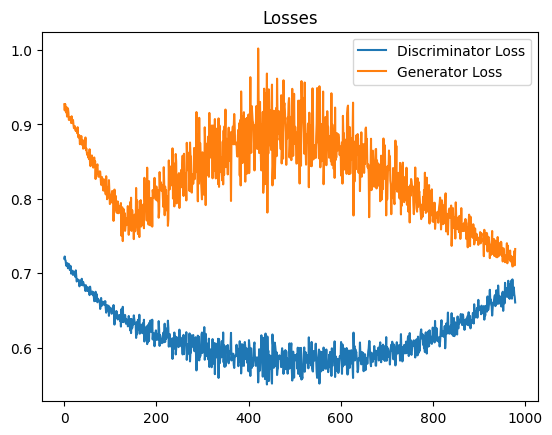

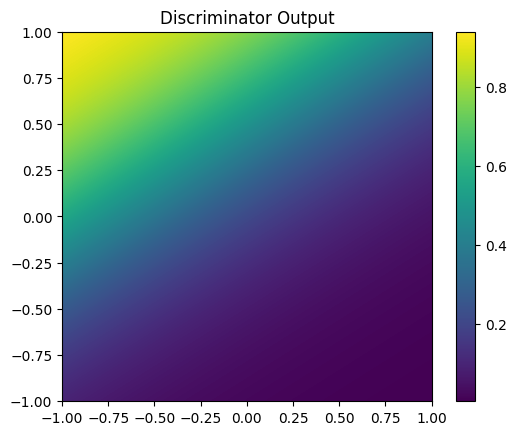

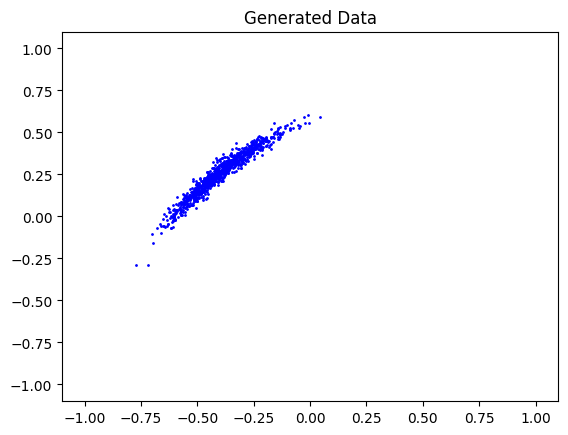

In [18]:
visualize_loss(loss_D_values, loss_G_values)
visualize_discriminator(discriminator)
visualize_generator(generator, noise_dim)

Let us try with a more complex model:

<font color='blue'>**TODO:**</font> Complete the code below to implement a more complex generator and discriminator:
- Generator: Implement a neural network with 4 hidden layers of size 256, 512, 1024 with Leaky ReLU activation functions. The output layer should output a sample in dimension 2.
- Discriminator: Implement a neural network with 4 hidden layers of size 1024, 512, 256 with Leaky ReLU activation functions. The output layer should output a scalar between 0 and 1.

In [19]:
class DenseGenerator(nn.Module):
    def __init__(self, noise_dim=1, out_dim=2):
        super(DenseGenerator, self).__init__()
        self.fc1 = nn.Linear(noise_dim, 256)
        self.fc2 = nn.Linear(256, 512)
        self.fc3 = nn.Linear(512, 1024)
        self.fc4 = nn.Linear(1024, out_dim)
        self.intermediate_activation = nn.LeakyReLU(0.2)
        self.out_activation = nn.Tanh()

    def forward(self, x):
        x = self.intermediate_activation(self.fc1(x))
        x = F.leaky_relu(self.fc2(x))
        x = F.leaky_relu(self.fc3(x))
        return self.out_activation(self.fc4(x))


class DenseDiscriminator(nn.Module):
    def __init__(self, in_dim=2):
        super(DenseDiscriminator, self).__init__()
        self.fc1 = nn.Linear(in_dim, 1024)
        self.fc2 = nn.Linear(1024, 512)
        self.fc3 = nn.Linear(512, 256)
        self.fc4 = nn.Linear(256, 1)
        self.out_activation = nn.Sigmoid()

    def forward(self, x):
        x = F.leaky_relu(self.fc1(x))
        x = F.leaky_relu(self.fc2(x))
        x = F.leaky_relu(self.fc3(x))
        return self.out_activation(self.fc4(x))

<font color='blue'>**TODO:**</font> Run the code below to train the GAN on 2D data with a more complex model. Observe the generated samples and the discriminator. 

In [20]:
noise_dim = 10
batch_size = 100

generator = DenseGenerator(noise_dim).to(device)
discriminator = DenseDiscriminator().to(device)
print(
    f"Number of parameters in generator: {sum(p.numel() for p in generator.parameters())}"
)
print(
    f"Number of parameters in discriminator: {sum(p.numel() for p in discriminator.parameters())}"
)
optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002)
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002)

loss_D_values, loss_G_values = train_GAN(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    simple_2D_data,
    n_epochs=20,
    batch_size=100,
    num_steps=5,
)

Number of parameters in generator: 661762
Number of parameters in discriminator: 659457
Epoch 1/20 Loss D: 0.2954 Loss G: 2.7981
Epoch 2/20 Loss D: 0.4713 Loss G: 2.2191
Epoch 3/20 Loss D: 0.5860 Loss G: 1.2121
Epoch 4/20 Loss D: 0.5822 Loss G: 1.1518
Epoch 5/20 Loss D: 0.5658 Loss G: 1.1407
Epoch 6/20 Loss D: 0.6079 Loss G: 0.9702
Epoch 7/20 Loss D: 0.5893 Loss G: 0.9730
Epoch 8/20 Loss D: 0.6020 Loss G: 0.8813
Epoch 9/20 Loss D: 0.6391 Loss G: 0.8295
Epoch 10/20 Loss D: 0.6563 Loss G: 0.7989
Epoch 11/20 Loss D: 0.6712 Loss G: 0.7731
Epoch 12/20 Loss D: 0.6756 Loss G: 0.7536
Epoch 13/20 Loss D: 0.6737 Loss G: 0.7624
Epoch 14/20 Loss D: 0.6749 Loss G: 0.7468
Epoch 15/20 Loss D: 0.6800 Loss G: 0.7428
Epoch 16/20 Loss D: 0.6769 Loss G: 0.7418
Epoch 17/20 Loss D: 0.6740 Loss G: 0.7639
Epoch 18/20 Loss D: 0.6575 Loss G: 0.8306
Epoch 19/20 Loss D: 0.6320 Loss G: 0.9695
Epoch 20/20 Loss D: 0.4800 Loss G: 1.6694


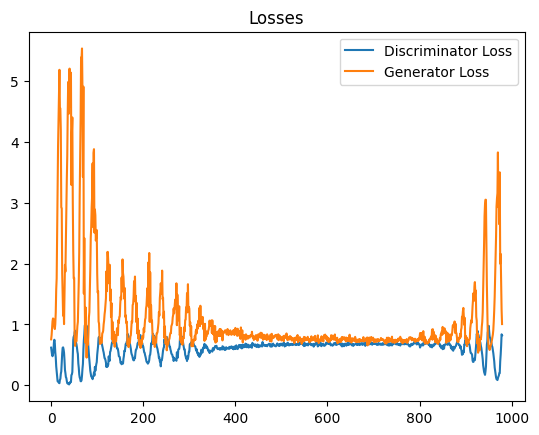

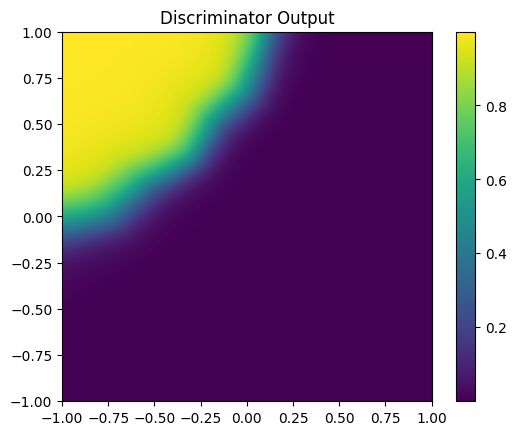

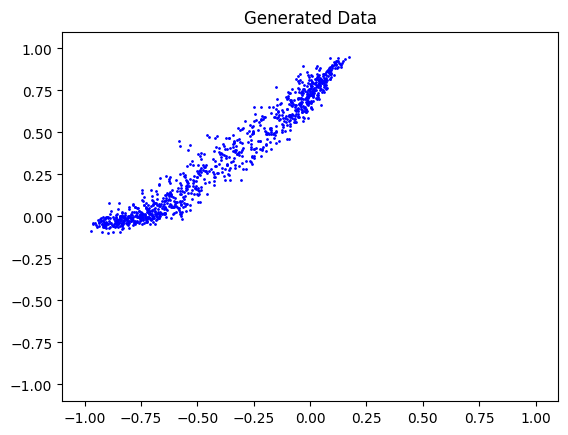

In [21]:
visualize_loss(loss_D_values, loss_G_values)
visualize_discriminator(discriminator)
visualize_generator(generator, noise_dim)

In [22]:
# Average accuracy over the eval

We will now try with 2D data slightly more complex:

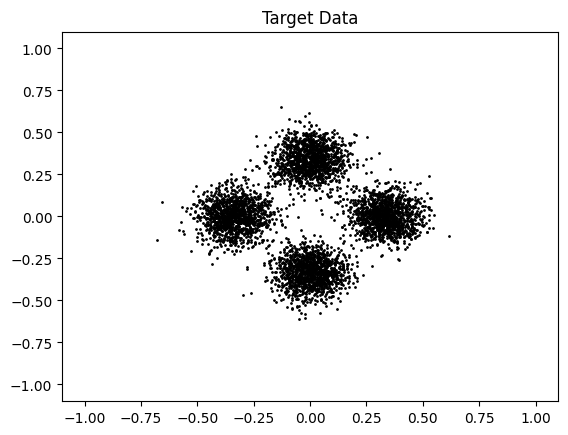

In [23]:
def complex_2D_data(n=1000):
    means = torch.Tensor([[-2, 0], [2, 0], [0, 2], [0, -2]])
    sigmas = torch.Tensor([0.5] * 4)
    n_per_cluster = n // 4
    data = []
    for i in range(4):
        data.append(
            torch.distributions.Normal(means[i], sigmas[i]).sample((n_per_cluster,))
        )
    data = torch.cat(data) / 6
    return data


dataset = complex_2D_data(n=5000)
plt.scatter(dataset[:, 0], dataset[:, 1], c="black", s=1)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.title("Target Data")
plt.show()

<font color='blue'>**TODO:**</font> Run the code below to train the GAN on 2D data with a more complex model. Observe the generated samples and the discriminator.

In [24]:
noise_dim = 10
batch_size = 100

generator = DenseGenerator(noise_dim).to(device)
discriminator = DenseDiscriminator().to(device)

optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002)
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002)

loss_D_values, loss_G_values = train_GAN(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    complex_2D_data,
    n_epochs=20,
    batch_size=100,
    num_steps=5,
)

Epoch 1/20 Loss D: 0.5577 Loss G: 1.0302
Epoch 2/20 Loss D: 0.5163 Loss G: 1.3843
Epoch 3/20 Loss D: 0.6087 Loss G: 1.0417
Epoch 4/20 Loss D: 0.6324 Loss G: 0.9335
Epoch 5/20 Loss D: 0.6327 Loss G: 0.9217
Epoch 6/20 Loss D: 0.6271 Loss G: 0.8759
Epoch 7/20 Loss D: 0.6531 Loss G: 0.8534
Epoch 8/20 Loss D: 0.6497 Loss G: 0.8476
Epoch 9/20 Loss D: 0.6368 Loss G: 0.9393
Epoch 10/20 Loss D: 0.6177 Loss G: 0.9781
Epoch 11/20 Loss D: 0.6346 Loss G: 0.9282
Epoch 12/20 Loss D: 0.6674 Loss G: 0.8137
Epoch 13/20 Loss D: 0.6906 Loss G: 0.7106
Epoch 14/20 Loss D: 0.6874 Loss G: 0.7203
Epoch 15/20 Loss D: 0.6595 Loss G: 0.7974
Epoch 16/20 Loss D: 0.6378 Loss G: 0.8901
Epoch 17/20 Loss D: 0.6359 Loss G: 0.9093
Epoch 18/20 Loss D: 0.6886 Loss G: 0.7517
Epoch 19/20 Loss D: 0.6982 Loss G: 0.6971
Epoch 20/20 Loss D: 0.6813 Loss G: 0.7156


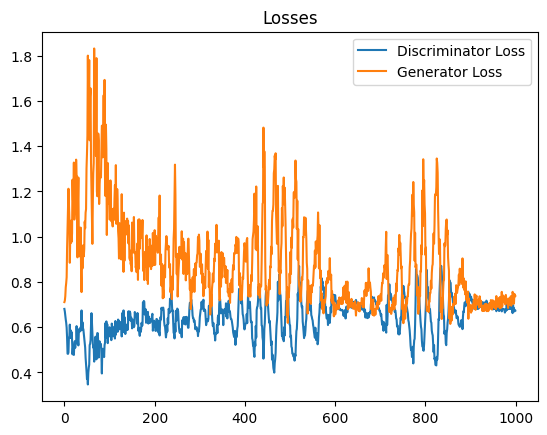

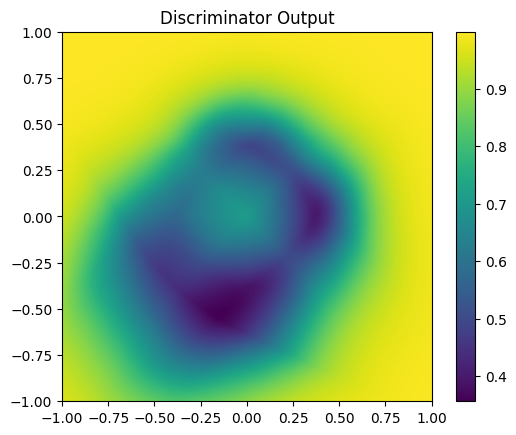

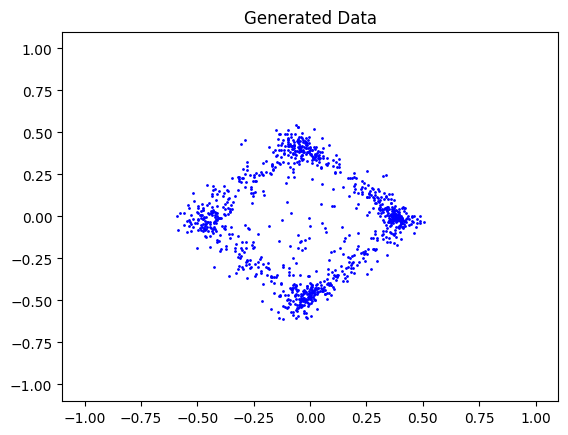

In [25]:
visualize_loss(loss_D_values, loss_G_values)
visualize_discriminator(discriminator)
visualize_generator(generator, noise_dim)

The GAN model is know for being hard to train for two main reasons:
- Mode collapse: The generator collapses to a single point and generates the same sample.
- Model instability: The generator and discriminator are trained simultaneously and the training can be unstable.

We can observe the model collapse easilly with the 2D data on this dataset:


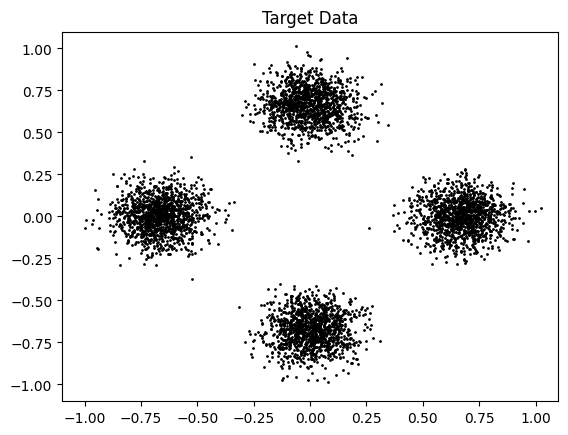

In [26]:
def complex_large_2D_data(n=1000):
    means = torch.Tensor([[-4, 0], [4, 0], [0, 4], [0, -4]])
    sigmas = torch.Tensor([0.6] * 4)
    n_per_cluster = n // 4
    data = []
    for i in range(4):
        data.append(
            torch.distributions.Normal(means[i], sigmas[i]).sample((n_per_cluster,))
        )
    data = torch.cat(data) / 6
    return data


dataset = complex_large_2D_data(n=5000)
plt.scatter(dataset[:, 0], dataset[:, 1], c="black", s=1)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.title("Target Data")
plt.show()

<font color='blue'>**TODO:**</font> Run the code below to train the GAN on 2D data with a more complex model. Conclude on mode collapse.

In [27]:
noise_dim = 10
batch_size = 100

generator = DenseGenerator(noise_dim).to(device)
discriminator = DenseDiscriminator().to(device)

optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002)
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002)

loss_D_values, loss_G_values = train_GAN(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    complex_large_2D_data,
    n_epochs=20,
    batch_size=100,
    num_steps=5,
)

Epoch 1/20 Loss D: 0.3038 Loss G: 2.2538
Epoch 2/20 Loss D: 0.3452 Loss G: 2.4415
Epoch 3/20 Loss D: 0.3906 Loss G: 2.1762
Epoch 4/20 Loss D: 0.4598 Loss G: 1.8119
Epoch 5/20 Loss D: 0.5069 Loss G: 1.4459
Epoch 6/20 Loss D: 0.5349 Loss G: 1.3248
Epoch 7/20 Loss D: 0.5591 Loss G: 1.2349
Epoch 8/20 Loss D: 0.5651 Loss G: 1.1681
Epoch 9/20 Loss D: 0.5789 Loss G: 1.1049
Epoch 10/20 Loss D: 0.5733 Loss G: 1.2029
Epoch 11/20 Loss D: 0.5824 Loss G: 1.1465
Epoch 12/20 Loss D: 0.6061 Loss G: 1.0183
Epoch 13/20 Loss D: 0.6176 Loss G: 0.9844
Epoch 14/20 Loss D: 0.6182 Loss G: 0.9666
Epoch 15/20 Loss D: 0.6312 Loss G: 0.9328
Epoch 16/20 Loss D: 0.6215 Loss G: 0.9935
Epoch 17/20 Loss D: 0.6128 Loss G: 1.0323
Epoch 18/20 Loss D: 0.5999 Loss G: 1.0740
Epoch 19/20 Loss D: 0.6225 Loss G: 0.9492
Epoch 20/20 Loss D: 0.6451 Loss G: 0.8648


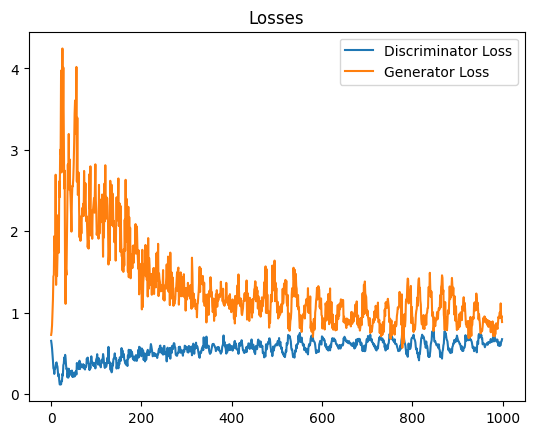

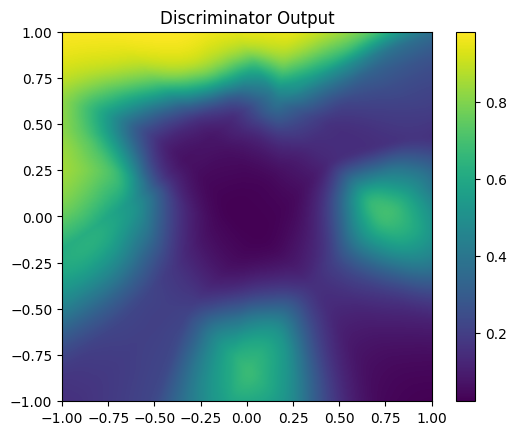

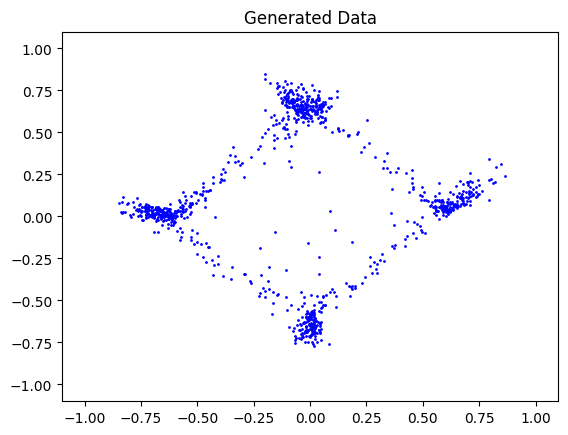

In [28]:
visualize_loss(loss_D_values, loss_G_values)
visualize_discriminator(discriminator)
visualize_generator(generator, noise_dim)

# 3. GAN on MNIST

We will now implement a GAN to generate handwritten digits from the MNIST dataset. The MNIST dataset consists of 28x28 grayscale images of handwritten digits from 0 to 9. We will use the same architectyre as before. For compuational reasons, we will use a rescaled version of the MNIST dataset with images of size 'size'x'size'.

In [29]:
size = 14

The code below loads the MNIST dataset and rescales the images to the desired size.

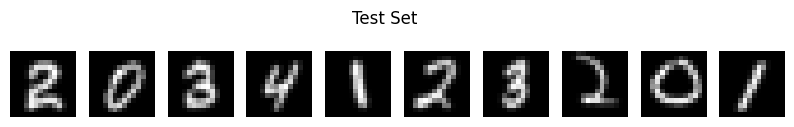

In [30]:
# Transform to resize, convert to tensor, and flatten to a vector of size (size)
transform = transforms.Compose(
    [
        transforms.Resize((size, size)),  # Resize to sizexsize pixels
        transforms.ToTensor(),  # Convert to a tensor with shape (1, size, size)
        transforms.Lambda(
            lambda x: x.view(size * size)
        ),  # Flatten to (size*size,) and normalize
        transforms.Lambda(
            lambda x: 2 * x - 1
        ),  # Normalize to [-1, 1] to avoid overflow
    ]
)


# Custom dataset to filter only labels 0 and 1
class FilteredMNIST(datasets.MNIST):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Filter to keep only images with labels 0 and 1
        indices = [
            i for i, label in enumerate(self.targets) if label in [0, 1, 2, 3, 4]
        ]
        self.data = self.data[indices]
        self.targets = self.targets[indices]

    def __getitem__(self, index):
        # Return only the image, not the label
        image, _ = super().__getitem__(index)
        return image


# Create datasets and loaders
dataset_train = FilteredMNIST(
    root="./data", train=True, download=True, transform=transform
)
dataset_test = FilteredMNIST(
    root="./data", train=False, download=True, transform=transform
)

loader_train = torch.utils.data.DataLoader(dataset_train, batch_size=128, shuffle=True)
loader_test = torch.utils.data.DataLoader(dataset_test, batch_size=128, shuffle=True)

first_batch = next(iter(loader_test))

plt.figure(1, figsize=(10, 10))
plt.suptitle("Test Set", y=0.57)
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(first_batch[i].view(size, size).numpy(), cmap="gray")
    plt.axis("off")
plt.show()

The function below will plot the generated samples from the generator.

In [31]:
def plot_images(generator, noise_dim):
    generator.eval()
    noise = input_noise(10, noise_dim=noise_dim).to(device)
    generated_images = generator(noise).detach().cpu()
    generated_images = (generated_images + 1) / 2
    plt.figure(figsize=(10, 1))
    for i in range(10):
        plt.subplot(1, 10, i + 1)
        plt.imshow(generated_images[i].view(size, size).numpy(), cmap="gray")
        plt.axis("off")
    plt.show()

As usual for image data, we will split the data into batches of size `batch_size`. The training loop must be adapted to train the GAN on image data. 

<font color='blue'>**TODO:**</font> Complete the code below to implement the training loop for the GAN on MNIST. At each epoch, we iterate over the batches of the dataset and train the GAN.

In [32]:
def train_GAN_MNIST(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    n_epochs=20,
    num_steps=1,
):
    loss_D_values = []
    loss_G_values = []

    for epoch in range(n_epochs):
        avg_loss_D = 0
        avg_loss_G = 0

        for data in loader_train:
            data = data.to(device)
            noise = input_noise(len(data), noise_dim=noise_dim).to(device)
            loss_D, loss_G = training_step(
                generator,
                discriminator,
                optimizer_D,
                optimizer_G,
                noise,
                data,
                num_steps=num_steps,
            )
            loss_D_values.append(loss_D)
            loss_G_values.append(loss_G)
            avg_loss_D += loss_D
            avg_loss_G += loss_G

        print(
            f"Epoch {epoch+1}/{n_epochs} Loss D: {avg_loss_D/len(loader_train):.4f} Loss G: {avg_loss_G/len(loader_train):.4f}"
        )
        if epoch % 5 == 0:
            plot_images(generator, noise_dim)

    return loss_D_values, loss_G_values

<font color='blue'>**TODO:**</font> Run the code below to train the GAN on MNIST.

Epoch 1/100 Loss D: 0.3936 Loss G: 2.6056


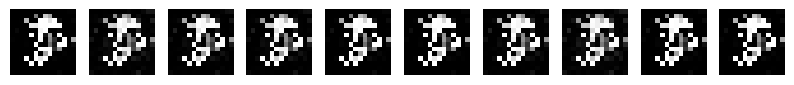

Epoch 2/100 Loss D: 0.0392 Loss G: 7.3804
Epoch 3/100 Loss D: 0.2296 Loss G: 12.5139
Epoch 4/100 Loss D: 0.2167 Loss G: 6.6601
Epoch 5/100 Loss D: 0.1283 Loss G: 5.0295
Epoch 6/100 Loss D: 0.2278 Loss G: 6.1011


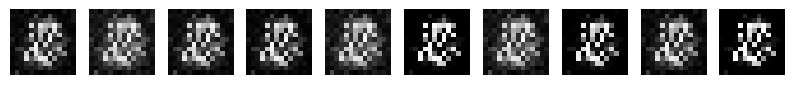

Epoch 7/100 Loss D: 0.1638 Loss G: 5.9034
Epoch 8/100 Loss D: 0.2329 Loss G: 5.0865
Epoch 9/100 Loss D: 0.2035 Loss G: 4.5850
Epoch 10/100 Loss D: 0.2066 Loss G: 4.3379
Epoch 11/100 Loss D: 0.1654 Loss G: 4.0731


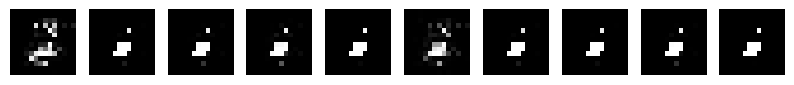

Epoch 12/100 Loss D: 0.1723 Loss G: 4.2544
Epoch 13/100 Loss D: 0.1584 Loss G: 4.0479
Epoch 14/100 Loss D: 0.1403 Loss G: 4.6753
Epoch 15/100 Loss D: 0.1774 Loss G: 3.9705
Epoch 16/100 Loss D: 0.1401 Loss G: 4.0493


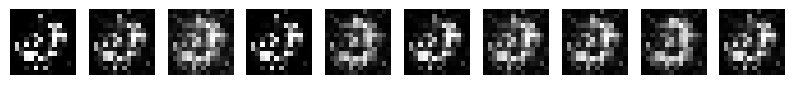

Epoch 17/100 Loss D: 0.1830 Loss G: 4.1024
Epoch 18/100 Loss D: 0.1787 Loss G: 4.0638
Epoch 19/100 Loss D: 0.1882 Loss G: 4.3604
Epoch 20/100 Loss D: 0.1259 Loss G: 4.0498


In [ ]:
noise_dim = 100
generator = DenseGenerator(noise_dim, out_dim=size * size).to(device)
discriminator = DenseDiscriminator(in_dim=size * size).to(device)

optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002)
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002)

loss_D_values, loss_G_values = train_GAN_MNIST(
    generator,
    discriminator,
    optimizer_D,
    optimizer_G,
    noise_dim,
    n_epochs=100,
    num_steps=1,
)

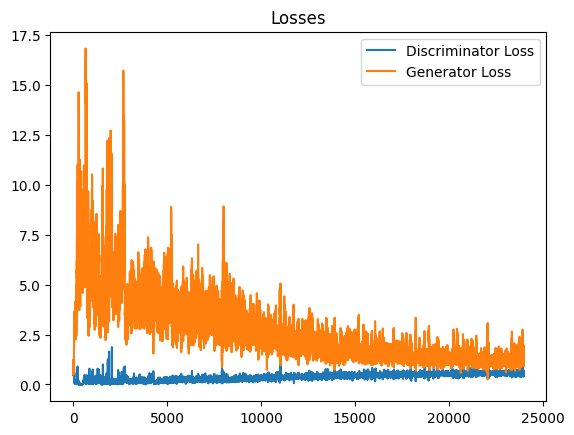

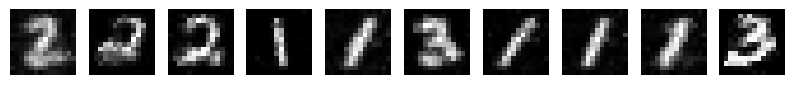

In [ ]:
visualize_loss(loss_D_values, loss_G_values)
plot_images(generator, noise_dim)

In [ ]:
noise = torch.randn(10, noise_dim).to(device)
generated_images = generator(noise)
d_fake = discriminator(generated_images)

print(
    f"Discriminator output on generated images: {d_fake.mean():.2f} pm {d_fake.std():.2f}"
)

first_batch = next(iter(loader_train))
d_real = discriminator(first_batch.view(-1, size * size).to(device))
print(f"Discriminator output on real images: {d_real.mean():.2f} pm {d_real.std():.2f}")

Discriminator output on generated images: 0.28 pm 0.17
Discriminator output on real images: 0.56 pm 0.23
